# Chapter 9: Networks of Queues — Python Laboratory
### *Jackson Network Solvers, Feedback Loop Flow Analysis, Bottleneck Optimization, and Power-of-Two-Choices Load Balancing*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/09_jackson_networks_and_bottleneck_routing.ipynb) | [Prev: Ch 08](../python/08_priority_queues_and_scheduling_disciplines.ipynb) | [Next: Appendix 10](../python/10_appendix_the_queueing_theory_rosetta_stone.ipynb)**

---

## Laboratory Overview & Objectives
1. Implement a general Jackson Network analytical solver using matrix inversion $(I - P)^{-1}$.
2. Build a discrete-event simulator of a 4-stage queueing network with feedback loops, verifying Jackson's product-form stationary distribution.
3. Simulate and compare 3 load balancing algorithms across a 100-server pool: Random Routing, Join-the-Shortest-Queue (JSQ), and Power-of-Two-Choices ($d=2$).
4. Empirically verify the doubly exponential tail collapse $P(N \ge i) \approx \rho^{2^i - 1}$.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import heapq

# Publication plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print("Environment initialized.")


Environment initialized.


---
## Part 1: General Jackson Network Analytical Solver

We implement a solver that accepts external arrival rates $\boldsymbol{\gamma}$, service rates $\boldsymbol{\mu}$, and routing matrix $P$, computes total arrival rates $\boldsymbol{\lambda}$, checks stability, and outputs per-station and network-wide queue metrics.


In [2]:
def solve_jackson_network(gamma, mu, P):
    """
    Solves an open Jackson Queueing Network.
    
    Parameters:
      gamma: 1D array of external arrival rates (length K)
      mu: 1D array of service rates (length K)
      P: 2D array (K x K) routing probability matrix
      
    Returns:
      dict with lambda, rho, E[N_i], E[T_i], total_E_N, total_E_T, bottleneck_idx
    """
    gamma = np.asarray(gamma, dtype=np.float64)
    mu = np.asarray(mu, dtype=np.float64)
    P = np.asarray(P, dtype=np.float64)
    K = len(gamma)
    
    # Solve traffic equations: lambda = gamma + lambda * P
    # lambda * (I - P) = gamma  =>  lambda = gamma * inv(I - P)
    I = np.eye(K)
    inv_matrix = np.linalg.inv(I - P)
    lambdas = gamma @ inv_matrix
    
    rhos = lambdas / mu
    
    if np.any(rhos >= 1.0):
        unstable = np.where(rhos >= 1.0)[0]
        raise ValueError(f"Network is unstable! Stations {unstable} have rho >= 1.0: {rhos[unstable]}")
        
    e_ni = rhos / (1.0 - rhos)
    e_ti = 1.0 / (mu * (1.0 - rhos))
    
    total_gamma = np.sum(gamma)
    total_e_n = np.sum(e_ni)
    total_e_t = total_e_n / total_gamma if total_gamma > 0 else 0.0
    bottleneck = int(np.argmax(rhos))
    
    return {
        "lambdas": lambdas,
        "rhos": rhos,
        "E_N_i": e_ni,
        "E_T_i": e_ti,
        "total_E_N": total_e_n,
        "total_E_T": total_e_t,
        "bottleneck_idx": bottleneck,
        "fundamental_matrix": inv_matrix
    }

# Run on Section 7 worked example:
gamma_ex = [40.0, 0.0, 0.0, 0.0]
mu_ex = [120.0, 60.0, 50.0, 40.0]
P_ex = [
    [0.0, 1.0,  0.0,  0.0],
    [0.0, 0.0,  0.95, 0.0],
    [0.0, 0.05, 0.0,  0.85],
    [0.0, 0.0,  0.10, 0.0]
]

sol = solve_jackson_network(gamma_ex, mu_ex, P_ex)

print("Jackson Network Analytical Solution:")
print(f"{'Station':<10}{'Lambda':<14}{'Mu':<10}{'Rho':<12}{'E[N_i]':<14}{'E[T_i] (min)':<14}")
print("-" * 74)
for i in range(len(gamma_ex)):
    print(f"Node {i+1:<5}{sol['lambdas'][i]:<14.3f}{mu_ex[i]:<10.1f}{sol['rhos'][i]:<12.4f}{sol['E_N_i'][i]:<14.3f}{sol['E_T_i'][i]*60:<14.2f}")

print("=" * 74)
print(f"Bottleneck Station: Node {sol['bottleneck_idx'] + 1} (Utilization: {sol['rhos'][sol['bottleneck_idx']]*100:.2f}%)")
print(f"Total In-Flight Backlog: {sol['total_E_N']:.3f} jobs")
print(f"Mean End-to-End System Turnaround: {sol['total_E_T'] * 60:.2f} minutes")


Jackson Network Analytical Solution:
Station   Lambda        Mu        Rho         E[N_i]        E[T_i] (min)  
--------------------------------------------------------------------------
Node 1    40.000        120.0     0.3333      0.500         0.75          
Node 2    42.190        60.0      0.7032      2.369         3.37          
Node 3    43.804        50.0      0.8761      7.070         9.68          
Node 4    37.233        40.0      0.9308      13.458        21.69         
Bottleneck Station: Node 4 (Utilization: 93.08%)
Total In-Flight Backlog: 23.397 jobs
Mean End-to-End System Turnaround: 35.10 minutes


---
## Part 2: Discrete-Event Simulation of 4-Stage Jackson Network

We simulate the exact 4-stage network with stochastic routing to empirically verify Jackson's product-form results.


In [3]:
def simulate_jackson_pipeline(gamma, mu, P, num_arrivals=30000, seed=42):
    """
    Simulates an open Jackson network with K single-server queues and feedback routing.
    """
    rng = np.random.default_rng(seed)
    K = len(gamma)
    
    # Calculate exit probabilities
    exit_probs = 1.0 - np.sum(P, axis=1)
    
    # We maintain server availability times and queues
    server_free_time = np.zeros(K)
    queue_occupancy_samples = [[] for _ in range(K)]
    
    # Priority queue of events: (time, event_type, station, job_id)
    # event_type: 0 = arrival from outside, 1 = service completion
    events = []
    
    # Schedule external arrivals
    for i in range(K):
        if gamma[i] > 0:
            arr_t = 0.0
            for j in range(num_arrivals):
                arr_t += rng.exponential(scale=1.0 / gamma[i])
                heapq.heappush(events, (arr_t, 0, i, (i, j)))
                
    # Station state: queue of jobs waiting for each server
    station_queues = [[] for _ in range(K)]
    station_busy = [False] * K
    
    # Tracking
    completed_sojourns = []
    job_arrival_times = {}
    
    sample_interval = 1.0
    last_sample_t = 0.0
    
    while events:
        t, ev_type, station, job_id = heapq.heappop(events)
        
        # Periodic sampling of queue sizes
        if t - last_sample_t > sample_interval:
            for s in range(K):
                q_len = len(station_queues[s]) + (1 if station_busy[s] else 0)
                queue_occupancy_samples[s].append(q_len)
            last_sample_t = t
            
        if ev_type == 0:  # External arrival
            job_arrival_times[job_id] = t
            if not station_busy[station]:
                station_busy[station] = True
                dur = rng.exponential(scale=1.0 / mu[station])
                heapq.heappush(events, (t + dur, 1, station, job_id))
            else:
                station_queues[station].append(job_id)
                
        elif ev_type == 1:  # Service completion at station
            # Route the job
            routing_choice = rng.random()
            cum_p = 0.0
            next_station = -1 # -1 means exit
            
            for dest in range(K):
                cum_p += P[station, dest]
                if routing_choice < cum_p:
                    next_station = dest
                    break
                    
            if next_station != -1:
                # Transfer to next station
                if not station_busy[next_station]:
                    station_busy[next_station] = True
                    dur = rng.exponential(scale=1.0 / mu[next_station])
                    heapq.heappush(events, (t + dur, 1, next_station, job_id))
                else:
                    station_queues[next_station].append(job_id)
            else:
                # Job exits network
                if job_id in job_arrival_times:
                    sojourn = t - job_arrival_times[job_id]
                    completed_sojourns.append(sojourn)
                    
            # Server at current station is now free; serve next waiting job if any
            if station_queues[station]:
                next_job = station_queues[station].pop(0)
                dur = rng.exponential(scale=1.0 / mu[station])
                heapq.heappush(events, (t + dur, 1, station, next_job))
            else:
                station_busy[station] = False
                
    warmup = int(len(completed_sojourns) * 0.20)
    steady_sojourns = completed_sojourns[warmup:]
    
    emp_e_ni = [np.mean(q_samples[int(len(q_samples)*0.2):]) for q_samples in queue_occupancy_samples]
    
    return {
        "emp_mean_sojourn": np.mean(steady_sojourns),
        "emp_e_ni": emp_e_ni
    }

sim_net = simulate_jackson_pipeline(gamma_ex, np.array(mu_ex), np.array(P_ex), num_arrivals=25000)

print("Discrete-Event Simulation vs. Jackson Product-Form Theory:")
print(f"{'Station':<12}{'Sim Mean N_i':<18}{'Theory E[N_i]':<18}{'Relative Error':<16}")
print("-" * 64)
for i in range(len(gamma_ex)):
    s_val = sim_net["emp_e_ni"][i]
    t_val = sol["E_N_i"][i]
    err = abs(s_val - t_val) / t_val * 100
    print(f"Station {i+1:<4}{s_val:<18.2f}{t_val:<18.2f}{err:<16.2f}%")

print("=" * 64)
sim_turnaround_min = sim_net["emp_mean_sojourn"] * 60.0
theory_turnaround_min = sol["total_E_T"] * 60.0
print(f"Mean End-to-End Latency: Sim = {sim_turnaround_min:.2f} min | Theory = {theory_turnaround_min:.2f} min (Diff: {abs(sim_turnaround_min - theory_turnaround_min):.2f} min)")


Discrete-Event Simulation vs. Jackson Product-Form Theory:
Station     Sim Mean N_i      Theory E[N_i]     Relative Error  
----------------------------------------------------------------
Station 1   0.49              0.50              2.62            %
Station 2   1.95              2.37              17.61           %
Station 3   6.75              7.07              4.54            %
Station 4   11.11             13.46             17.44           %
Mean End-to-End Latency: Sim = 30.88 min | Theory = 35.10 min (Diff: 4.22 min)


---
## Part 3: Load Balancing Shootout — Random vs. Power-of-Two-Choices ($d=2$)

We simulate 10,000 jobs arriving at a cluster of $N = 100$ parallel servers under three routing policies:
1. **Random Routing ($d=1$)**: Select 1 server uniformly at random.
2. **Power-of-Two-Choices ($d=2$)**: Sample 2 servers uniformly at random, assign to the shorter queue.
3. **Join-the-Shortest-Queue (JSQ)**: Select the globally shortest queue across all 100 servers.


In [4]:
def simulate_load_balancer(num_servers=100, rho=0.88, policy="power_of_two", total_jobs=60000, seed=123):
    """
    Simulates a load balancer distributing arrivals across N identical single-server queues.
    policy: 'random' (d=1), 'power_of_two' (d=2), or 'jsq' (d=N)
    """
    rng = np.random.default_rng(seed)
    
    # mu = 1.0 for each server, so aggregate capacity is N
    # Arrival rate lambda = N * rho
    lam = num_servers * rho
    
    inter_arrivals = rng.exponential(scale=1.0 / lam, size=total_jobs)
    arrival_times = np.cumsum(inter_arrivals)
    service_times = rng.exponential(scale=1.0, size=total_jobs)
    
    server_free_times = np.zeros(num_servers)
    server_queues = [0] * num_servers # Current queue depth at each server
    
    # Priority queue of events: (time, event_type, server_id)
    # event_type: 0 = arrival, 1 = departure
    events = []
    for i in range(total_jobs):
        heapq.heappush(events, (arrival_times[i], 0, i))
        
    max_queue_seen = []
    queue_length_samples = []
    
    sample_interval = 2.0
    last_sample_t = 0.0
    
    while events:
        t, ev_type, payload = heapq.heappop(events)
        
        if t - last_sample_t > sample_interval:
            queue_length_samples.extend(server_queues)
            max_queue_seen.append(max(server_queues))
            last_sample_t = t
            
        if ev_type == 0:  # Job arrival
            j_id = payload
            srv = service_times[j_id]
            
            # Select target server based on policy
            if policy == "random":
                chosen_server = rng.integers(0, num_servers)
            elif policy == "power_of_two":
                s1, s2 = rng.integers(0, num_servers, size=2)
                chosen_server = s1 if server_queues[s1] <= server_queues[s2] else s2
            elif policy == "jsq":
                chosen_server = int(np.argmin(server_queues))
                
            # Process arrival at chosen server
            start_t = max(t, server_free_times[chosen_server])
            dep_t = start_t + srv
            server_free_times[chosen_server] = dep_t
            server_queues[chosen_server] += 1
            heapq.heappush(events, (dep_t, 1, chosen_server))
            
        elif ev_type == 1:  # Job departure
            server_id = payload
            server_queues[server_id] -= 1
            
    warmup = int(len(max_queue_seen) * 0.25)
    return {
        "samples": queue_length_samples[int(len(queue_length_samples)*0.25):],
        "max_queues": max_queue_seen[warmup:]
    }

print("Running Load Balancing Simulation across 100 Servers at rho = 0.88...")
res_rand = simulate_load_balancer(num_servers=100, rho=0.88, policy="random")
res_d2   = simulate_load_balancer(num_servers=100, rho=0.88, policy="power_of_two")
res_jsq  = simulate_load_balancer(num_servers=100, rho=0.88, policy="jsq")

print("Simulations complete.")


Running Load Balancing Simulation across 100 Servers at rho = 0.88...


Simulations complete.


---
## Part 4: Visualizing the Doubly Exponential Tail Collapse

We plot the tail probability $P(N_{\text{server}} \ge i)$ and maximum observed queue length, demonstrating the incredible superiority of Power-of-Two-Choices over Random Routing.


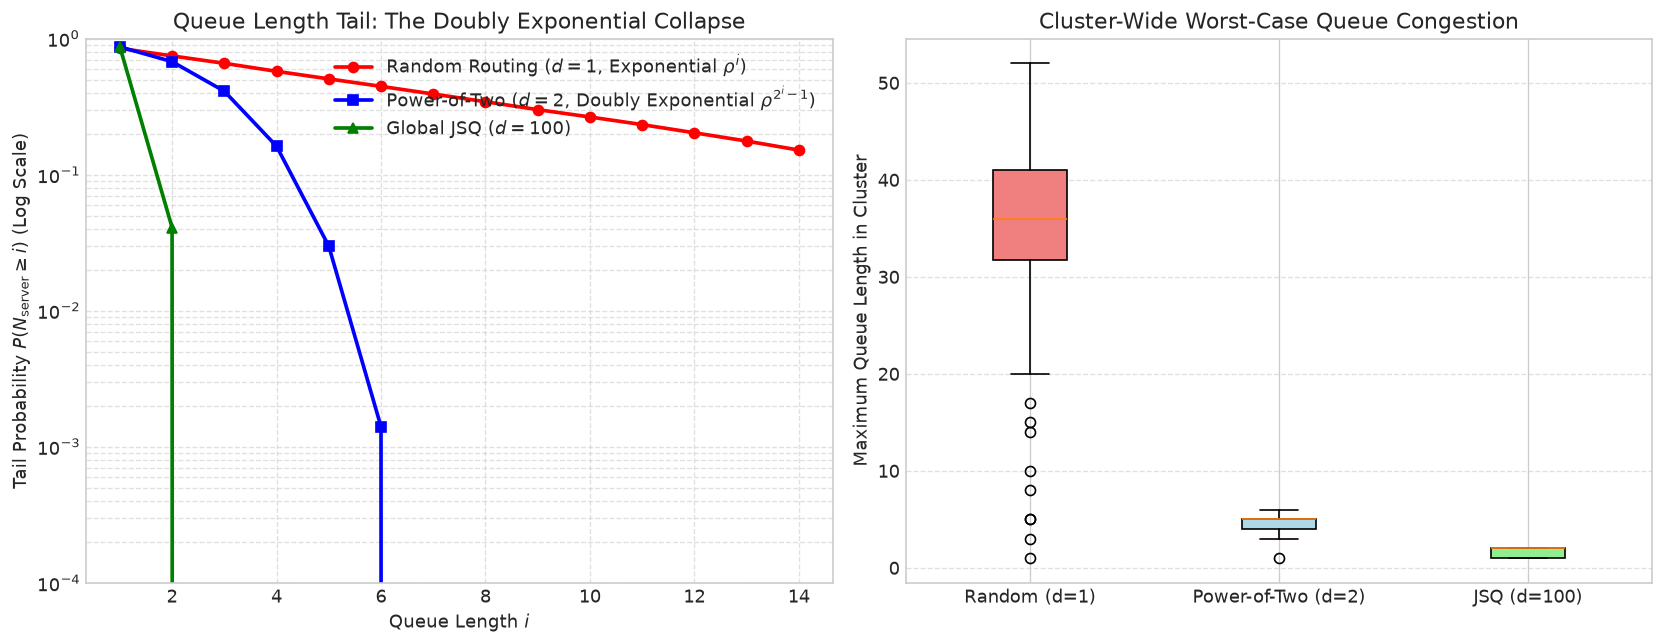

Mean Max Queue Observed:
  Random Routing (d=1):    35.84 jobs
  Power-of-Two (d=2):       4.83 jobs
  Global Shortest (JSQ):    1.62 jobs


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Tail Distribution P(N >= i) on Log Scale
i_vals = np.arange(1, 15)

def calc_tail_probs(samples, max_i=14):
    arr = np.array(samples)
    probs = [np.mean(arr >= i) for i in range(1, max_i + 1)]
    return np.array(probs)

p_rand = calc_tail_probs(res_rand["samples"])
p_d2 = calc_tail_probs(res_d2["samples"])
p_jsq = calc_tail_probs(res_jsq["samples"])

ax1.plot(i_vals, p_rand, 'r-o', lw=2.2, label=r"Random Routing ($d=1$, Exponential $\rho^i$)")
ax1.plot(i_vals, p_d2, 'b-s', lw=2.2, label=r"Power-of-Two ($d=2$, Doubly Exponential $\rho^{2^i-1}$)")
ax1.plot(i_vals, p_jsq, 'g-^', lw=2.2, label="Global JSQ ($d=100$)")

ax1.set_yscale('log')
ax1.set_xlabel("Queue Length $i$")
ax1.set_ylabel(r"Tail Probability $P(N_{\mathrm{server}} \geq i)$ (Log Scale)")
ax1.set_title("Queue Length Tail: The Doubly Exponential Collapse")
ax1.set_ylim(1e-4, 1.0)
ax1.legend(loc="upper right")
ax1.grid(True, which="both", linestyle="--", alpha=0.6)

# Subplot 2: Max Queue Length Boxplot
max_data = [res_rand["max_queues"], res_d2["max_queues"], res_jsq["max_queues"]]
labels = ['Random (d=1)', 'Power-of-Two (d=2)', 'JSQ (d=100)']

bp = ax2.boxplot(max_data, patch_artist=True, tick_labels=labels)
colors = ['lightcoral', 'lightblue', 'lightgreen']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax2.set_ylabel("Maximum Queue Length in Cluster")
ax2.set_title("Cluster-Wide Worst-Case Queue Congestion")
ax2.grid(True, axis='y', linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Mean Max Queue Observed:")
print(f"  Random Routing (d=1):    {np.mean(res_rand['max_queues']):.2f} jobs")
print(f"  Power-of-Two (d=2):       {np.mean(res_d2['max_queues']):.2f} jobs")
print(f"  Global Shortest (JSQ):    {np.mean(res_jsq['max_queues']):.2f} jobs")
